> **Versão pública (2026).** Notebook original, executado em 2021 no Windows (Python 3.7, Anaconda), com as bibliotecas na mesma pasta. As saídas são as originais. Para rodar de novo, veja o [README desta pasta](README.md).

In [1]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import StratifiedShuffleSplit, ShuffleSplit
from sklearn.model_selection import StratifiedKFold, KFold

######################

import AleTransforms as trf
import AleDatasetAnalysis as dsa

import AleLearners as lrn
import AleMLAnalysis as aml

import AleExplainers as exp

In [2]:
import importlib

importlib.reload(trf)
importlib.reload(dsa)

importlib.reload(lrn)
importlib.reload(aml)

importlib.reload(exp)

<module 'AleExplainers' from '<PASTA_DAS_BIBLIOTECAS>\\AleExplainers.py'>

In [3]:
df = pd.read_excel('datasets/titanic_full.xls')

In [4]:
df.loc[:, df.dtypes == 'int64'] = df.loc[:, df.dtypes == 'int64'].astype(float)

In [5]:
df_nulls = pd.DataFrame(df.isnull().sum(), columns = ['QTD'])
df_nulls = df_nulls[df_nulls['QTD'] > 0]
df_nulls = df_nulls.sort_values('QTD', ascending = True)
display(df_nulls)

QTD
fare          1
embarked      2
age         263
home.dest   564
boat        823
cabin      1014
body       1188

In [6]:
list(df.columns)

['pclass',
 'survived',
 'name',
 'sex',
 'age',
 'sibsp',
 'parch',
 'ticket',
 'fare',
 'cabin',
 'embarked',
 'boat',
 'body',
 'home.dest']

# CortaIntervalosQuasiUniforme

In [7]:
vetor = df['age'].dropna().values

In [8]:
interv = trf.CortaIntervalosQuasiUniforme(vetor, num_div = 10)

In [9]:
interv.info_discretizacao()

QTD      Min    Max      Meio          Str
0   72   0.1667   8.50   4.33335  [0.17, 8.5)
1   82   8.5000  17.50  13.00000    [8.5, 18)
2   95  17.5000  20.75  19.12500     [18, 21)
3  112  20.7500  23.75  22.25000     [21, 24)
4  143  23.7500  27.50  25.62500     [24, 28)
5  130  27.5000  31.50  29.50000     [28, 32)
6  121  31.5000  36.25  33.87500     [32, 36)
7   96  36.2500  42.50  39.37500     [36, 42)
8  100  42.5000  50.50  46.50000     [42, 50)
9   95  50.5000  80.00  65.25000     [50, 80)

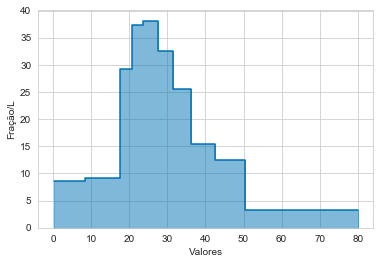

In [10]:
interv.grafico_densidade()

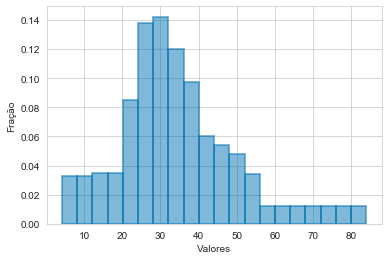

In [11]:
interv.grafico_distribuicao(bins = 20)

# Algoritmo

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import animation

In [13]:
def calcula_intervalos_algasignif(valores_min, valores_max):
    valores_corte = np.append(valores_min, valores_max[-1])
    alga_signif = 1
    str_conv = ''.join(['%.', np.str(alga_signif), 'g'])
    cortes_interv = np.array([float(str_conv % valores_corte[i]) for i in range(valores_corte.size)])
    flag = trf.calcula_min_diff(cortes_interv) #não pode ter pontos de corte iguais
    while flag == 0:
        alga_signif += 1
        str_conv = ''.join(['%.', np.str(alga_signif), 'g'])
        cortes_interv = np.array([float(str_conv % valores_corte[i]) for i in range(valores_corte.size)])
        flag = trf.calcula_min_diff(cortes_interv)
    strings = [str(v) for v in cortes_interv]
    strings = [v if v[-2:] != '.0' else v[:-2] for v in strings]
    return np.array(['['+strings[i]+', '+strings[i+1]+')' for i in range(valores_corte.size-1)])

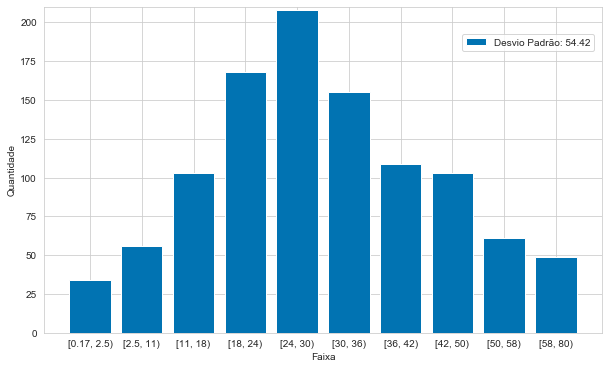

In [14]:
valores, qtds, qtd_unicos = trf.unicos_qtds(vetor)
pts_corte, qtds_corte = trf.pontos_corte(qtds, qtd_unicos, num_div = 10)
valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)

ymax = np.max(qtds_corte)*1.01
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [10, 6])
    ax.bar(strings_intervalos, qtds_corte, color = paleta_cores[0], label = 'Desvio Padrão: ' + '%.4g' % np.std(qtds_corte))
    ax.set_xlabel('Faixa')
    ax.set_ylabel('Quantidade')
    ax.set_ylim(bottom = 0.0)
    ax.set_ylim(top = ymax)
    ax.legend(bbox_to_anchor = (0.74, 0.93), loc='upper left')
    plt.show()

In [15]:
def minimiza_desvio_padrao(pts_corte, qtds_corte, qtds, qtd_unicos):
    fim = pts_corte.size - 1
    prefim = fim - 1
    permutado = True
    lista_plots = [] # ALTERADO
    while(permutado):
        
        # ALTERADO
        valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
        strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
        for k in range(0, 4):
            lista_plots.append(('ini_loop', strings_intervalos, qtds_corte.copy()))
        #########
        
        permutado = False
        for i in range(fim): # ALTERADO
            a = qtds_corte[prefim-i]
            b = qtds_corte[fim-i]
            p = pts_corte[prefim-i]
            qe = qtds[p]
            qd = qtds[p+1]
            if(a - b > qe and a > qe):
                qtds_corte[fim-i] = b + qe
                qtds_corte[prefim-i] = a - qe
                pts_corte[prefim-i] = p - 1
                permutado = True
                
                # ALTERADO
                valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
                strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
                lista_plots.append(('', strings_intervalos, qtds_corte.copy()))
                #########
                
            elif(b - a > qd and b > qd):
                qtds_corte[fim-i] = b - qd
                qtds_corte[prefim-i] = a + qd
                pts_corte[prefim-i] = p + 1
                permutado = True
                
                # ALTERADO
                valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
                strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
                lista_plots.append(('', strings_intervalos, qtds_corte.copy()))
                #########
                
    return pts_corte, qtds_corte, lista_plots # ALTERADO

In [16]:
pts_corte, qtds_corte, lista_plots = minimiza_desvio_padrao(pts_corte, qtds_corte, qtds, qtd_unicos)
valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)

for k in range(0, 10):
    lista_plots.append(('fim', strings_intervalos, qtds_corte.copy()))

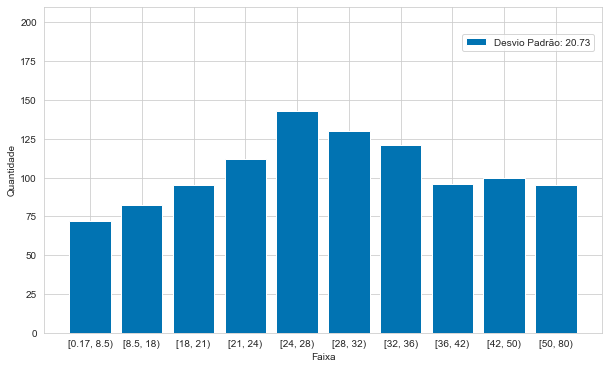

In [17]:
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [10, 6])
    ax.bar(strings_intervalos, qtds_corte, color = paleta_cores[0], label = 'Desvio Padrão: ' + '%.4g' % np.std(qtds_corte))
    ax.set_xlabel('Faixa')
    ax.set_ylabel('Quantidade')
    ax.set_ylim(bottom = 0.0)
    ax.set_ylim(top = ymax)
    ax.legend(bbox_to_anchor = (0.74, 0.93), loc='upper left')
    plt.show()

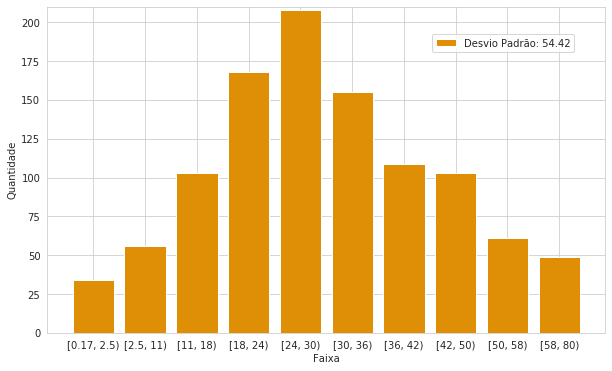

In [18]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [10, 6])
    
def animate(i):
    qtds_plot = lista_plots[i][2]
    strings_intervalos_plot = lista_plots[i][1]
    flag_color = lista_plots[i][0]
    with sns.axes_style("whitegrid"):
        ax.cla()
        if(flag_color == 'ini_loop'):
            ax.bar(strings_intervalos_plot, qtds_plot, color = paleta_cores[1], label = 'Desvio Padrão: ' + '%.4g' % np.std(qtds_plot))
        elif(flag_color == 'fim'):
            ax.bar(strings_intervalos_plot, qtds_plot, color = paleta_cores[2], label = 'Desvio Padrão: ' + '%.4g' % np.std(qtds_plot))
        else:
            ax.bar(strings_intervalos_plot, qtds_plot, color = paleta_cores[0], label = 'Desvio Padrão: ' + '%.4g' % np.std(qtds_plot))
        ax.legend(bbox_to_anchor = (0.68, 0.93), loc='upper left')
        ax.set_xlabel('Faixa')
        ax.set_ylabel('Quantidade')
        ax.set_ylim(bottom = 0.0)
        ax.set_ylim(top = ymax)

anim = animation.FuncAnimation(fig, animate, frames = len(lista_plots), interval = 1000, blit = False, repeat = True)
plt.show()
anim.save('imagens/ilustracao_algoritmo.gif', writer = 'pillow', fps = 5)

# Classificador Exemplo

In [19]:
colunas_id = ['name', 'ticket', 'cabin', 'boat', 'body', 'home.dest']

In [20]:
nome_alvo = 'survived'

In [21]:
vars_cat = ['sex', 'pclass', 'embarked']
vars_num = ['age', 'sibsp', 'parch', 'fare']

In [22]:
frac_teste = 0.2

ss_teste = StratifiedShuffleSplit(n_splits = 1, test_size = frac_teste, random_state = 42)
split_teste = list(ss_teste.split(df.values, df[nome_alvo].values))[0] 

df_intermed = df.iloc[split_teste[0]]
df_teste = df.iloc[split_teste[1]]

In [23]:
frac_val = 0.5
num_splits = 5

ss = StratifiedShuffleSplit(n_splits = num_splits, test_size = frac_val, random_state = 42)
#ss = StratifiedKFold(n_splits = num_splits, shuffle = True, random_state = 42)
lista_splits = list(ss.split(df_intermed.values, df_intermed[nome_alvo].values))  

In [24]:
tratador = trf.TrataDataset(df_intermed, num_div = None, num_cat = None, 
                            features_numericas = vars_num,
                            features_categoricas = vars_cat)
tratador.cria_one_hot_encoder(df_intermed, considera_resto = True, usar_str = True)

df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)

In [25]:
dict_Xy = {}

i = 0
for par in lista_splits:
    df_treino = df_intermed.iloc[par[0]]
    df_val = df_intermed.iloc[par[1]]
    
    df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
    df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
    
    #dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo]),
    #           'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    dict_Xy.update({'Treino_' + str(i+1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo])})
    #dict_Xy.update({'Treino_' + str(i+1): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    i = i + 1

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 141
Calculando as Normalizações das Features
Número de Parâmetros: 134
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
12.475235939025879


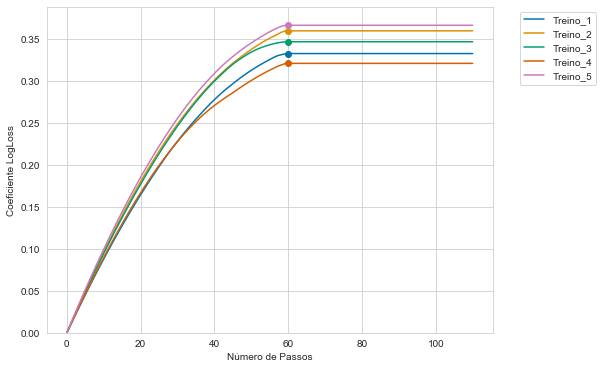

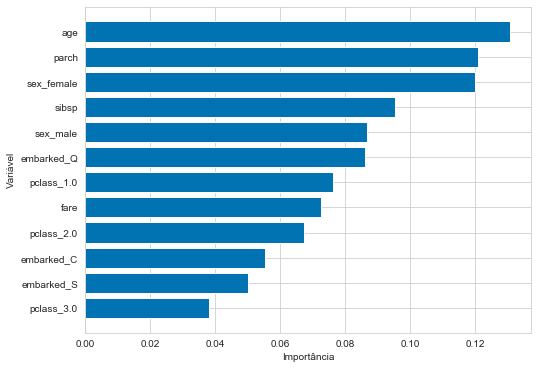

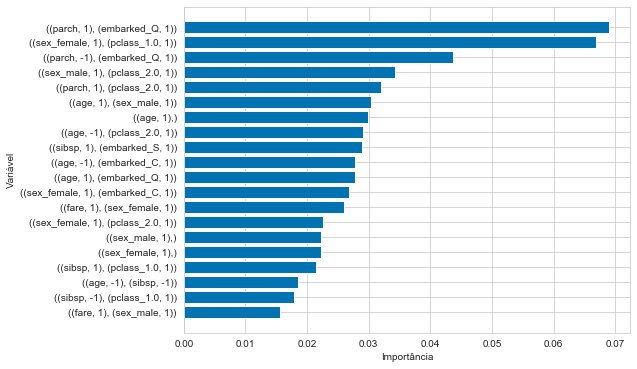

In [26]:
t = time.time()

clf = lrn.SeriesMultiGradientClassifier()
clf.setup_datasets(dict_Xy, laurent = True, ordem = 2, apenas_interacoes = False)
clf.setup_optimizer(alpha = 0.01, epsilon = 1e-8, early_stop = 50, filtro_atualizacao_thetas = True)
clf.fit(num_passos = 1000, verbose = 0, plot = False)

print(time.time() - t)

clf.grafico_vies_variancia(ymin = 0)
clf.grafico_importancias()
clf.grafico_importancias_termos(num_vars = 20)

In [27]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
probs_intermed = clf.predict_proba(df_intermed_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]
probs_teste = clf.predict_proba(df_teste_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]

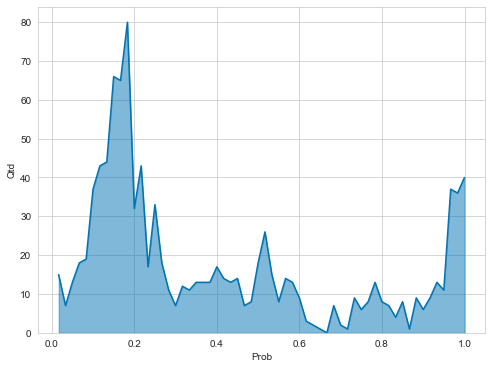

In [28]:
qtds, probs = np.histogram(probs_intermed, bins = 60)

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    axs.plot(probs[1:], qtds, color = paleta_cores[0])
    axs.fill_between(probs[1:], qtds, color = paleta_cores[0], alpha = 0.5)
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel('Prob')
    axs.set_ylabel('Qtd')
    #axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

In [29]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Prob'] = probs_intermed
df_teste_aval['Prob'] = probs_teste

In [30]:
dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaoclf = aml.AvaliaDatasetsClassificacao(dict_dfs, 
                                               nome_alvo, 
                                               'Prob', 
                                               num_div_prob = None, 
                                               num_div = 10, 
                                               num_cat = 3, 
                                               unit = None, 
                                               chave_treino = 'Treino')

In [31]:
avaliacaoclf.valor_metricas().loc[['LogLoss', 'CoefLogLoss', 'CoefLogLoss_ref',
                                  'AUC', 'KS', 'IG', 'IG_2D', 'Frac_Incerto_2D', 
                                  'Prob_Corte', 'Prob0_Corte', 'Prob1_Corte',
                                  'Acurácia_Balanceada', 'Acurácia_Balanceada_2D',
                                  'P(0|0)', 'P_2D(0|0)', 'Frac_0',
                                  'P(1|1)', 'P_2D(1|1)', 'Frac_1'], :]

Treino     Teste
LogLoss                 0.431018  0.412461
CoefLogLoss             0.351907  0.379646
CoefLogLoss_ref         0.351907  0.379646
AUC                     0.856304  0.878920
KS                      0.589030  0.636543
IG                      0.268810  0.329173
IG_2D                   0.337515  0.404487
Frac_Incerto_2D         0.257880  0.263359
Prob_Corte              0.516028  0.516232
Prob0_Corte             0.304838  0.270553
Prob1_Corte             0.757225  0.745969
Acurácia_Balanceada     0.779405  0.804877
Acurácia_Balanceada_2D  0.844587  0.870353
P(0|0)                  0.807692  0.827778
P_2D(0|0)               0.865149  0.884058
Frac_0                  0.617956  0.618321
P(1|1)                  0.815047  0.841463
P_2D(1|1)               0.936893  0.945455
Frac_1                  0.382044  0.381679

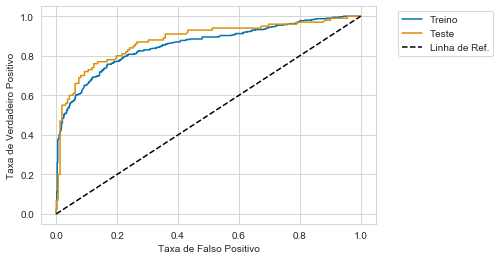

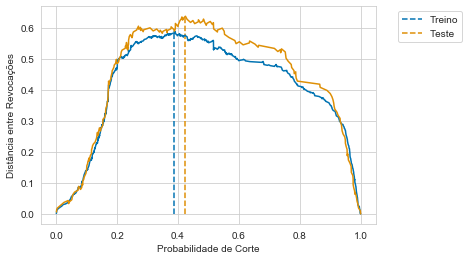

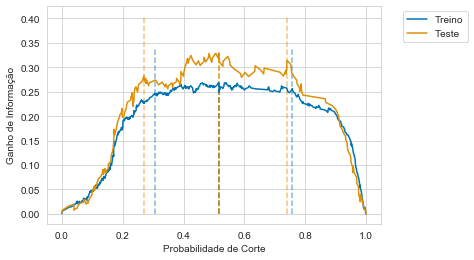

In [32]:
avaliacaoclf.grafico_roc()
avaliacaoclf.grafico_ks()
avaliacaoclf.grafico_informacao(mostrar_ig_2d = True)

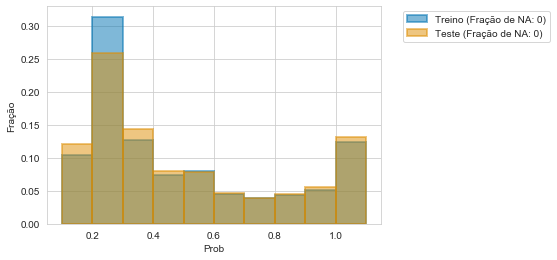

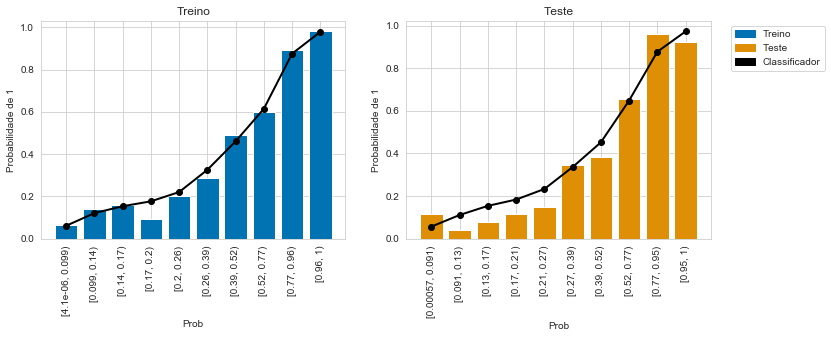

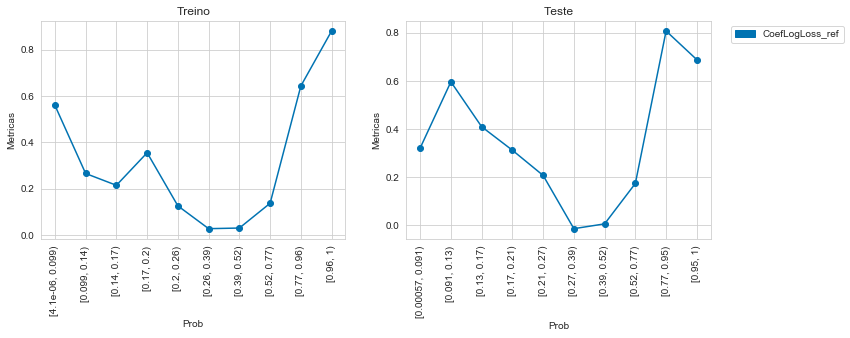

In [33]:
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Prob', num_div = 10, parametros_padrao = False)
avaliacaoclf.grafico_distribuicao('Prob')
avaliacaoclf.grafico_probabilidade_condicional('Prob', rot = 90)
avaliacaoclf.grafico_metricas_condicionais('Prob', metricas = ['CoefLogLoss_ref'], rot = 90)

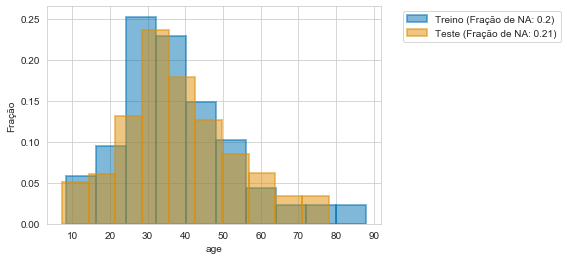

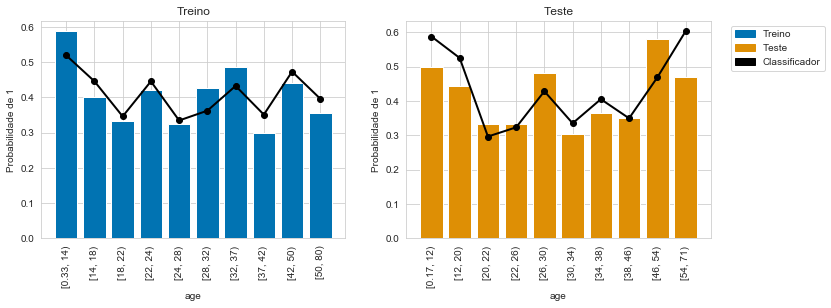

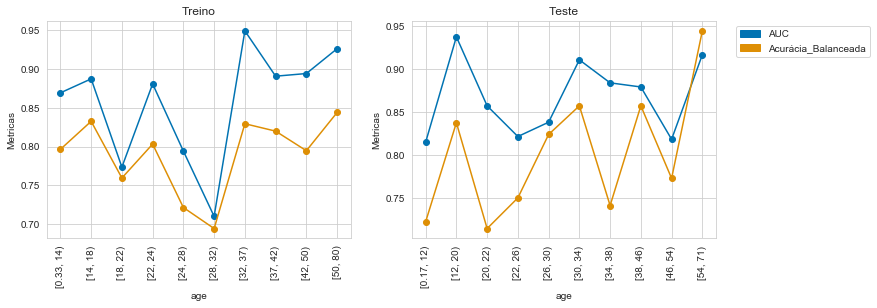

In [34]:
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'age')
avaliacaoclf.grafico_distribuicao('age')
avaliacaoclf.grafico_probabilidade_condicional('age', rot = 90)
avaliacaoclf.grafico_metricas_condicionais('age', metricas = ['AUC', 'Acurácia_Balanceada'], rot = 90)

# CortaIntervalosGanhoInformacao

vetor = df.loc[~df['fare'].isna(), 'fare'].values
alvo = df.loc[~df['fare'].isna(), 'survived'].values

vetor = df.loc[~df['age'].isna(), 'age'].values
alvo = df.loc[~df['age'].isna(), 'survived'].values

In [35]:
vetor = df_intermed_aval['Prob'].values
alvo = df_intermed_aval['survived'].values

In [36]:
vetor_teste = df_teste_aval['Prob'].values
alvo_teste = df_teste_aval['survived'].values

In [37]:
interv_ig = trf.CortaIntervalosGanhoInformacao(vetor, alvo, qtd_min = 50, num_div = 5, balancear = True)

In [38]:
interv_ig.info_discretizacao()

QTD  QTD_Alvos       Min       Max      Meio               Str
0   51        2.0  0.000004  0.066301  0.033152  [4.1e-06, 0.066)
1   55        4.0  0.066301  0.097492  0.081897    [0.066, 0.097)
2  789      245.0  0.097492  0.881977  0.489735     [0.097, 0.88)
3   65       64.0  0.881977  0.963303  0.922640      [0.88, 0.96)
4   87       85.0  0.963303  0.999834  0.981569         [0.96, 1)

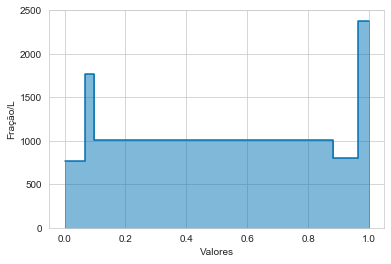

In [39]:
interv_ig.grafico_densidade()

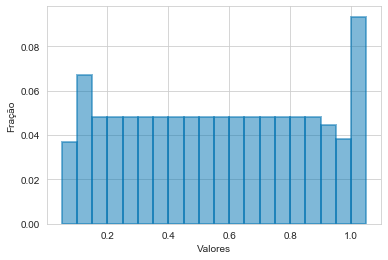

In [40]:
interv_ig.grafico_distribuicao(bins = 20)

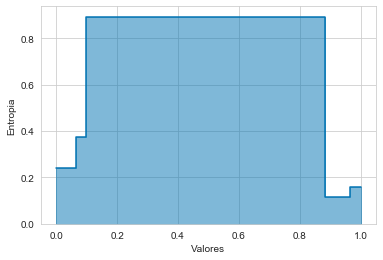

In [41]:
interv_ig.grafico_entropia()

In [42]:
interv_ig.ganho_informacao()

0.24422024506872841

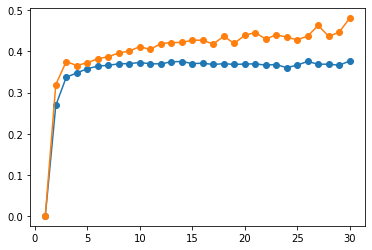

30
30


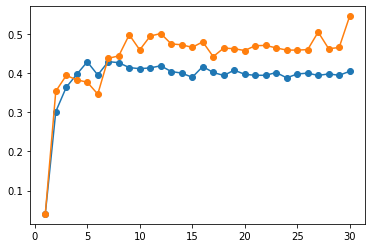

7
30


In [43]:
lista_ig = []
lista_ig_test = []
lista_ig_bal = []
lista_ig_test_bal = []
vrange = range(1, 31)
for i in vrange:
    interv_ig = trf.CortaIntervalosGanhoInformacao(vetor, alvo, qtd_min = 50, num_div = i, balancear = False)
    lista_ig.append(interv_ig.ganho_informacao())
    lista_ig_test.append(interv_ig.calcula_ig(vetor_teste, alvo_teste))
    lista_ig_bal.append(interv_ig.ganho_informacao_balanceado())
    lista_ig_test_bal.append(interv_ig.calcula_ig_bal(vetor_teste, alvo_teste))


plt.plot(list(vrange), lista_ig, 'o-')
plt.plot(list(vrange), lista_ig_test, 'o-')
plt.show()
print(list(vrange)[np.argmax(lista_ig)])
print(list(vrange)[np.argmax(lista_ig_test)])

plt.plot(list(vrange), lista_ig_bal, 'o-')
plt.plot(list(vrange), lista_ig_test_bal, 'o-')
plt.show()
print(list(vrange)[np.argmax(lista_ig_bal)])
print(list(vrange)[np.argmax(lista_ig_test_bal)])

# Algoritmo

In [44]:
entropia_ini = - (np.sum(alvo)/alvo.size)*np.log2(np.sum(alvo)/alvo.size) - (1 - np.sum(alvo)/alvo.size)*np.log2(1 - np.sum(alvo)/alvo.size)
entropia_ini

0.9594728076385045

In [45]:
from numba import jit_module, jit, prange

In [46]:
def unicos_qtds_alvos(vetor, alvo):
    inds_sorted = np.argsort(vetor)
    vetor_sorted = vetor[inds_sorted]
    alvo_sorted = alvo[inds_sorted]
    valores = []
    qtds = []
    qtds_alvo = []
    qtd_unicos = 0
    v = np.nan
    qtd = 0
    qtd_alvo = 0
    for i in prange(vetor_sorted.size):
        if vetor_sorted[i] == v:
            qtd = qtd + 1
            qtd_alvo = qtd_alvo + alvo_sorted[i]
        else:
            valores.append(v)
            qtds.append(qtd)
            qtds_alvo.append(qtd_alvo)
            qtd_unicos = qtd_unicos + 1
            v = vetor_sorted[i]
            qtd = 1
            qtd_alvo = alvo_sorted[i]
    valores.append(v)
    qtds.append(qtd)
    qtds_alvo.append(qtd_alvo)
    return np.array(valores[1:]), np.array(qtds[1:]), np.array(qtds_alvo[1:]), qtd_unicos

def pontos_corte_alvo(qtds, qtd_unicos, qtds_alvo, num_div):
    passo = int(qtd_unicos/num_div)
    pts_corte = [i*passo for i in prange(num_div+1)]
    pts_corte[-1] = qtd_unicos
    qtds_corte = [np.sum(qtds[pts_corte[i]:pts_corte[i+1]]) for i in prange(num_div)]
    qtds_alvo_corte = [np.sum(qtds_alvo[pts_corte[i]:pts_corte[i+1]]) for i in prange(num_div)]
    pts_corte = [p - 1 for p in pts_corte[1:]]
    return np.array(pts_corte), np.array(qtds_corte), np.array(qtds_alvo_corte)

def funcao_comparacao_entropia(Qe, Ae, Qd, Ad):
    retorno = Qe*np.log2(Qe) + Qd*np.log2(Qd)
    if(Ae > 0):
        retorno = retorno - Ae*np.log2(Ae)
    if(Ae < Qe):
        retorno = retorno - (Qe-Ae)*np.log2(Qe-Ae)
    if(Ad > 0):
        retorno = retorno - Ad*np.log2(Ad)
    if(Ad < Qd):
        retorno = retorno - (Qd-Ad)*np.log2(Qd-Ad)
    return retorno

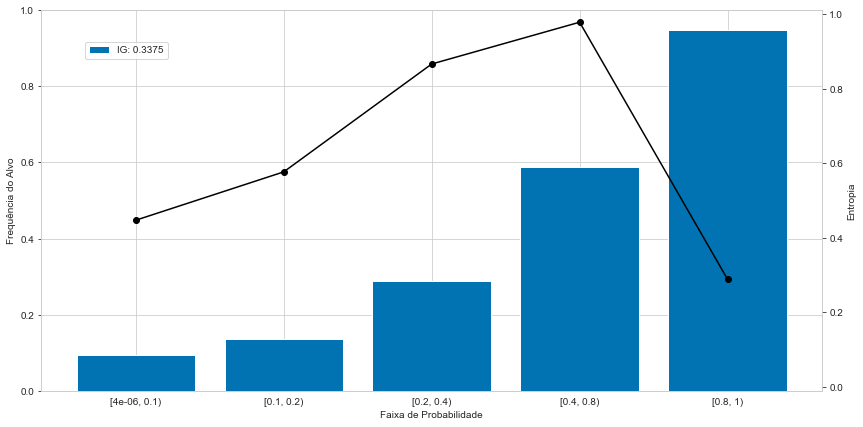

In [47]:
valores, qtds, qtds_alvo, qtd_unicos = unicos_qtds_alvos(vetor, alvo)
pts_corte, qtds_corte, qtds_alvo_corte = pontos_corte_alvo(qtds, qtd_unicos, qtds_alvo, num_div = 5)

valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)

ymax = np.max(qtds_alvo_corte/qtds_corte)*1.01
y2max = np.max(qtds_corte)*1.01
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [14, 7])
    entropia = np.sum(qtds_corte*trf.entropia_shannon(qtds_alvo_corte/qtds_corte))/np.sum(qtds_corte)
    ig = (entropia_ini - entropia)/entropia_ini
    ax.bar(strings_intervalos, qtds_alvo_corte/qtds_corte, color = paleta_cores[0], label = 'IG: ' + '%.4g' % ig)
    ax.set_xlabel('Faixa de Probabilidade')
    ax.set_ylabel('Frequência do Alvo')
    ax.set_ylim(bottom = 0.0)
    ax.set_ylim(top = 1.0)
    ax.legend(bbox_to_anchor = (0.05, 0.93), loc='upper left')
    ax2 = ax.twinx()
    ax2.grid(False)
    #ax2.plot(strings_intervalos, qtds_corte, 'o-', color = 'black')
    #ax2.set_ylabel('Quantidade de Exemplos')
    #ax2.set_ylim(top = y2max)
    ax2.plot(strings_intervalos, trf.entropia_shannon(qtds_alvo_corte/qtds_corte), 'o-', color = 'black')
    ax2.set_ylim(top = 1.01)
    ax2.set_ylabel('Entropia')
    ax2.set_ylim(bottom = -0.01)
    plt.show()

In [48]:
def minimiza_entropia(pts_corte, qtds_corte, qtds, qtds_alvo_corte, qtds_alvo, qtd_unicos):
    fim = pts_corte.size - 1
    prefim = fim - 1
    permutado = True
    lista_plots = [] # ALTERADO
    while(permutado):
        
        # ALTERADO
        valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
        strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
        for k in range(0, 1):
            lista_plots.append(('ini_loop', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy()))
        #########
        
        permutado = False
        for i in range(fim): # ALTERADO
            Qe = qtds_corte[prefim-i]
            Qd = qtds_corte[fim-i]
            Ae = qtds_alvo_corte[prefim-i]
            Ad = qtds_alvo_corte[fim-i]
            p = pts_corte[prefim-i]
            
            p_inf = 0 if i == prefim else pts_corte[prefim-i-1]
            e = p
            while(permutado == False and e > p_inf):
                qe = np.sum(qtds[e:p+1])
                ae = np.sum(qtds_alvo[e:p+1])
                if(Qe > qe and funcao_comparacao_entropia(Qe-qe, Ae-ae, Qd+qe, Ad+ae) < funcao_comparacao_entropia(Qe, Ae, Qd, Ad)):
                    qtds_corte[fim-i] = Qd + qe
                    qtds_corte[prefim-i] = Qe - qe
                    qtds_alvo_corte[fim-i] = Ad + ae
                    qtds_alvo_corte[prefim-i] = Ae - ae
                    pts_corte[prefim-i] = e - 1
                    permutado = True

                    # ALTERADO
                    valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
                    strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
                    lista_plots.append(('', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy()))
                    #########
                else:
                    e = e - 1
            
            p_sup = pts_corte[fim-i]
            d = p+1
            while(permutado == False and d < p_sup):
                qd = np.sum(qtds[p+1:d+1])
                ad = np.sum(qtds_alvo[p+1:d+1])
                if(Qd > qd and funcao_comparacao_entropia(Qe+qd, Ae+ad, Qd-qd, Ad-ad) < funcao_comparacao_entropia(Qe, Ae, Qd, Ad)):
                    qtds_corte[fim-i] = Qd - qd
                    qtds_corte[prefim-i] = Qe + qd
                    qtds_alvo_corte[fim-i] = Ad - ad
                    qtds_alvo_corte[prefim-i] = Ae + ad
                    pts_corte[prefim-i] = d
                    permutado = True

                    # ALTERADO
                    valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
                    strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
                    lista_plots.append(('', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy()))
                    #########
                else:
                    d = d + 1
                
    return pts_corte, qtds_corte, qtds_alvo_corte, lista_plots # ALTERADO

In [49]:
pts_corte, qtds_corte, qtds_alvo_corte, lista_plots = minimiza_entropia(pts_corte, qtds_corte, qtds, qtds_alvo_corte, qtds_alvo, qtd_unicos)
valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)

for k in range(0, 10):
    lista_plots.append(('fim', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy()))

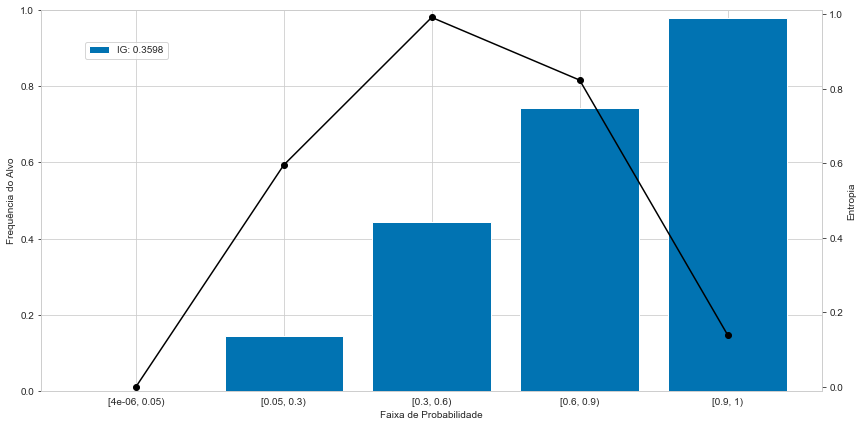

In [50]:
ymax = np.max(qtds_alvo_corte/qtds_corte)*1.01
y2max = np.max(qtds_corte)*1.01
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [14, 7])
    entropia = np.sum(qtds_corte*trf.entropia_shannon(qtds_alvo_corte/qtds_corte))/np.sum(qtds_corte)
    ig = (entropia_ini - entropia)/entropia_ini
    ax.bar(strings_intervalos, qtds_alvo_corte/qtds_corte, color = paleta_cores[0], label = 'IG: ' + '%.4g' % ig)
    ax.set_xlabel('Faixa de Probabilidade')
    ax.set_ylabel('Frequência do Alvo')
    ax.set_ylim(bottom = 0.0)
    ax.set_ylim(top = 1.0)
    ax.legend(bbox_to_anchor = (0.05, 0.93), loc='upper left')
    ax2 = ax.twinx()
    ax2.grid(False)
    #ax2.plot(strings_intervalos, qtds_corte, 'o-', color = 'black')
    #ax2.set_ylabel('Quantidade de Exemplos')
    #ax2.set_ylim(top = y2max)
    ax2.plot(strings_intervalos, trf.entropia_shannon(qtds_alvo_corte/qtds_corte), 'o-', color = 'black')
    ax2.set_ylim(top = 1.01)
    ax2.set_ylabel('Entropia')
    ax2.set_ylim(bottom = -0.01)
    plt.show()

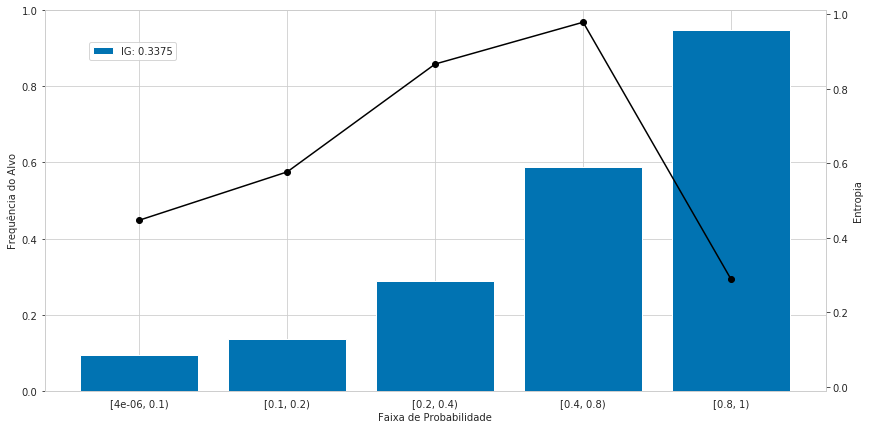

In [51]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [14, 7])
    ax2 = ax.twinx()
    
y2max = 0
for l in lista_plots:
    y2max = max(y2max, np.max(l[2]))
y2max = y2max*1.01
    
def animate(i):
    qtds_plot = lista_plots[i][2]
    strings_intervalos_plot = lista_plots[i][1]
    qtds_alvo_plot = lista_plots[i][3]
    flag_color = lista_plots[i][0]
    entropia = np.sum(qtds_plot*trf.entropia_shannon(qtds_alvo_plot/qtds_plot))/np.sum(qtds_plot)
    ig = (entropia_ini - entropia)/entropia_ini
    with sns.axes_style("whitegrid"):
        ax.cla()
        ax2.cla()
        if(flag_color == 'ini_loop'):
            ax.bar(strings_intervalos_plot, qtds_alvo_plot/qtds_plot, color = paleta_cores[0], label = 'IG: ' + '%.4g' % ig)
        elif(flag_color == 'fim'):
            ax.bar(strings_intervalos_plot, qtds_alvo_plot/qtds_plot, color = paleta_cores[2], label = 'IG: ' + '%.4g' % ig)
        else:
            ax.bar(strings_intervalos_plot, qtds_alvo_plot/qtds_plot, color = paleta_cores[0], label = 'IG: ' + '%.4g' % ig)
        ax.legend(bbox_to_anchor = (0.05, 0.93), loc='upper left')
        ax.set_xlabel('Faixa de Probabilidade')
        ax.set_ylabel('Frequência do Alvo')
        ax.set_ylim(bottom = 0.0)
        ax.set_ylim(top = 1.0)
        ax2.grid(False)
        #ax2.plot(strings_intervalos, qtds_corte, 'o-', color = 'black')
        #ax2.set_ylabel('Quantidade de Exemplos')
        #ax2.set_ylim(top = y2max)
        ax2.plot(strings_intervalos_plot, trf.entropia_shannon(qtds_alvo_plot/qtds_plot), 'o-', color = 'black')
        ax2.set_ylim(top = 1.01)
        ax2.set_ylabel('Entropia')
        ax2.set_ylim(bottom = -0.01)

anim = animation.FuncAnimation(fig, animate, frames = len(lista_plots), interval = 1000, blit = False, repeat = True)
plt.show()
anim.save('imagens/ilustracao_algoritmo_info.gif', writer = 'pillow', fps = 5)

# Regressor Exemplo

In [52]:
colunas_id = ['name', 'ticket', 'cabin', 'boat', 'body', 'home.dest', 'survived']

In [53]:
nome_alvo = 'age'

In [54]:
vars_cat = ['sex', 'pclass', 'embarked']
vars_num = ['sibsp', 'parch', 'fare']

In [55]:
df2 = df[~df['age'].isna()]

In [56]:
frac_teste = 0.2

ss_teste = ShuffleSplit(n_splits = 1, test_size = frac_teste, random_state = 42)
split_teste = list(ss_teste.split(df2.values, df2[nome_alvo].values))[0] 

df_intermed = df2.iloc[split_teste[0]]
df_teste = df2.iloc[split_teste[1]]

In [57]:
tratador = trf.TrataDataset(df_intermed, num_div = None, num_cat = None, 
                            features_numericas = vars_num,
                            features_categoricas = vars_cat)
tratador.cria_one_hot_encoder(df_intermed, considera_resto = True, usar_str = True)

df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)

In [58]:
frac_val = 0.2
num_splits = 4

ss = ShuffleSplit(n_splits = num_splits, test_size = frac_val, random_state = 42)
lista_splits = list(ss.split(df_intermed.values, df_intermed[nome_alvo].values))  

In [59]:
dict_Xy = {}

i = 0
for par in lista_splits:
    df_treino = df_intermed.iloc[par[0]]
    df_val = df_intermed.iloc[par[1]]
    
    df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
    df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
    
    dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo]),
               'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    #dict_Xy.update({'Treino_' + str(i+1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo])})
    
    i = i + 1

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 515
Calculando as Normalizações das Features
Número de Parâmetros: 370
Normalizando o Alvo
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
31.644542694091797


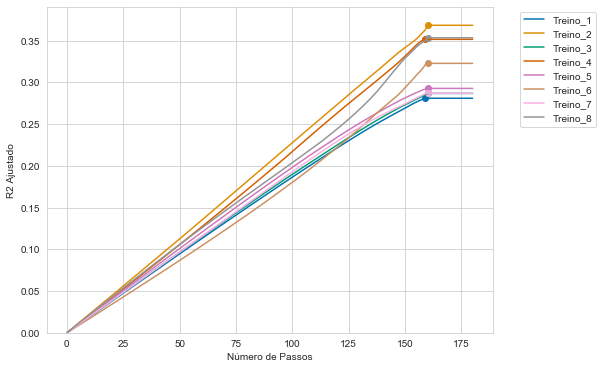

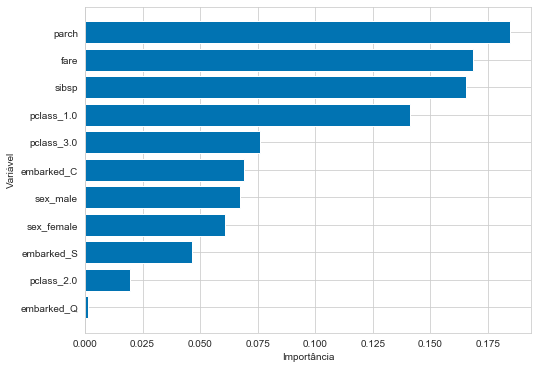

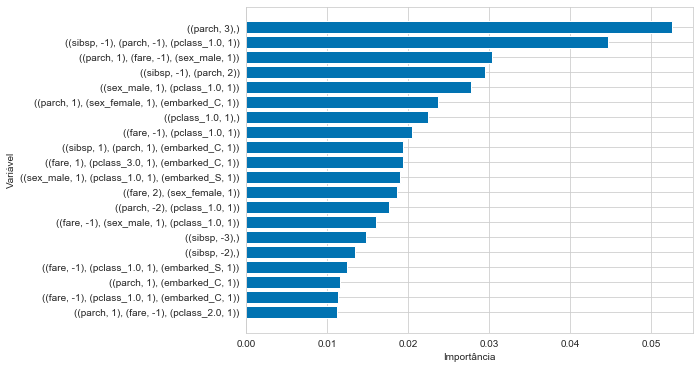

In [60]:
t = time.time()

rgs = lrn.SeriesMultiGradientRegressor()
rgs.setup_datasets(dict_Xy, laurent = True, ordem = 3, apenas_interacoes = False)
rgs.setup_optimizer(alpha = 0.001, epsilon = 1e-8, early_stop = 20, filtro_atualizacao_thetas = True)
rgs.fit(num_passos = 1000, verbose = 0, plot = False)

print(time.time() - t)

rgs.grafico_vies_variancia(ymin = 0)
rgs.grafico_importancias()
rgs.grafico_importancias_termos(num_vars = 20)

In [61]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
preds_intermed = rgs.predict(df_intermed_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))
preds_teste = rgs.predict(df_teste_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))

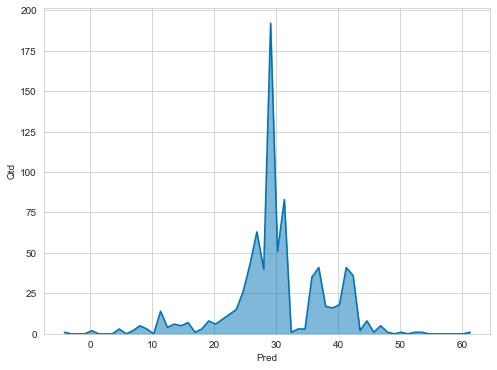

In [62]:
qtds, preds = np.histogram(preds_intermed, bins = 60)

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    axs.plot(preds[1:], qtds, color = paleta_cores[0])
    axs.fill_between(preds[1:], qtds, color = paleta_cores[0], alpha = 0.5)
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel('Pred')
    axs.set_ylabel('Qtd')
    #axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

In [63]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Pred'] = preds_intermed
df_teste_aval['Pred'] = preds_teste

In [64]:
dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaorgs = aml.AvaliaDatasetsRegressao(dict_dfs, 
                                               nome_alvo, 
                                               'Pred', 
                                               num_kendalltau = 10000, 
                                               num_div = 10, 
                                               num_cat = 3, 
                                               unit = None, 
                                               chave_treino = 'Treino')

In [65]:
avaliacaorgs.valor_metricas()

Treino        Teste
QTD                836.000000   210.000000
Soma_Alvo        24855.666700  6400.000000
Soma_Pred        24706.867782  6291.160175
Media_Alvo          29.731659    30.476190
Media_Pred          29.553670    29.957906
MAE                  9.471139     9.321878
MSE                150.209964   147.066970
RMSE                12.256017    12.127117
RAE                  0.825717     0.887051
RSE                  0.701746     0.811513
RRSE                 0.837703     0.900840
RAE_ref              0.825717     0.898985
RSE_ref              0.701746     0.809038
RRSE_ref             0.837703     0.899466
R1                   0.174283     0.112949
R2                   0.298254     0.188487
RR2                  0.162297     0.099160
R1_ref               0.174283     0.101015
R2_ref               0.298254     0.190962
RR2_ref              0.162297     0.100534
KendallTau_Conc      0.906500     0.802000
KendallTau_Disc      0.093500     0.198000
KendallTau           0.813000     0.604000

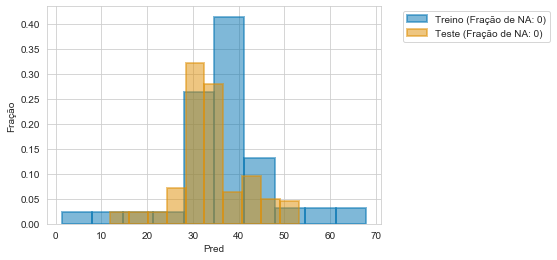

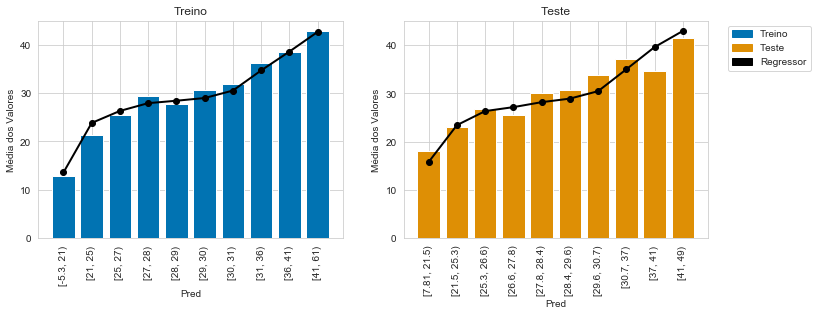

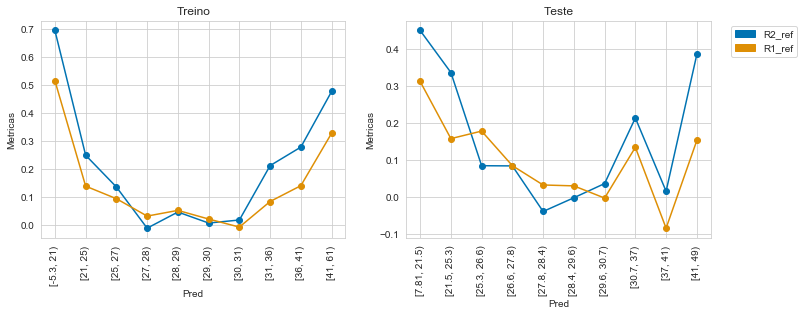

In [66]:
avaliacaorgs.calcula_metricas_condicionais(dict_dfs, 'Pred')
avaliacaorgs.grafico_distribuicao('Pred')
avaliacaorgs.grafico_media_condicional('Pred', rot = 90)
avaliacaorgs.grafico_metricas_condicionais('Pred', metricas = ['R2_ref', 'R1_ref'], rot = 90)

# CortaIntervalosR2

In [67]:
vetor = df_intermed_aval['Pred'].values
alvo = df_intermed_aval['age'].values

In [68]:
vetor_teste = df_teste_aval['Pred'].values
alvo_teste = df_teste_aval['age'].values

In [69]:
interv_r2 = trf.CortaIntervalosR2(vetor, alvo, qtd_min = 25, num_div = 5, balancear = False)

In [70]:
interv_r2.info_discretizacao()

QTD  QTD_Alvos        Min        Max       Meio         Str
0   54   545.4167  -5.328723  16.937729   5.804503  [-5.3, 17)
1   87  1662.0000  16.937729  24.731195  20.834462    [17, 25)
2  319  8726.3333  24.731195  28.888541  26.809868    [25, 29)
3  253  8664.0000  28.888541  38.386711  33.637626    [29, 38)
4  123  5257.9167  38.386711  61.252378  49.819545    [38, 61)

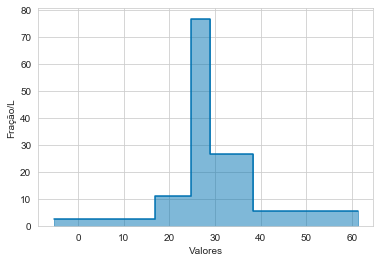

In [71]:
interv_r2.grafico_densidade()

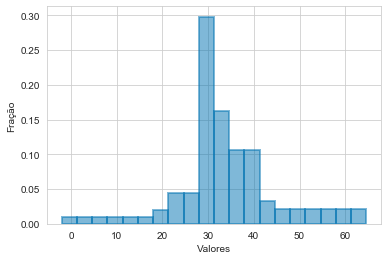

In [72]:
interv_r2.grafico_distribuicao(bins = 20)

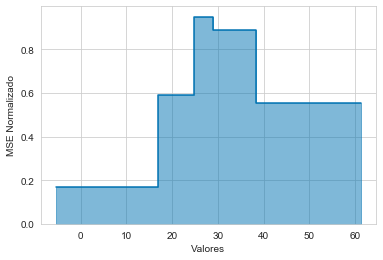

In [73]:
interv_r2.grafico_mse_normalizado()

In [74]:
interv_r2.r2()

0.3265250153551531

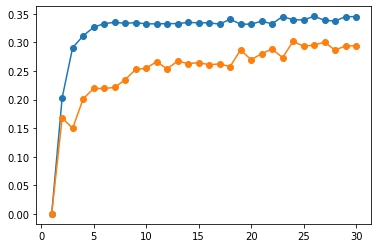

26
24


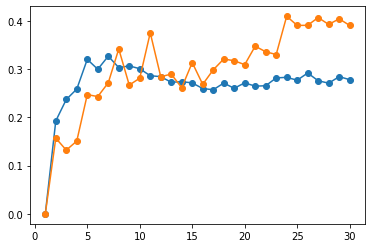

7
24


In [75]:
lista_r2 = []
lista_r2_teste = []
lista_r2_bal = []
lista_r2_teste_bal = []
vrange = range(1, 31)
for i in vrange:
    interv_r2 = trf.CortaIntervalosR2(vetor, alvo, qtd_min = 50, num_div = i, balancear = False)
    lista_r2.append(interv_r2.r2())
    lista_r2_teste.append(interv_r2.calcula_r2(vetor_teste, alvo_teste))
    lista_r2_bal.append(interv_r2.r2_balanceado())
    lista_r2_teste_bal.append(interv_r2.calcula_r2_bal(vetor_teste, alvo_teste))
    #print(interv_r2.r2())

plt.plot(list(vrange), lista_r2, 'o-')
plt.plot(list(vrange), lista_r2_teste, 'o-')
plt.show()
print(list(vrange)[np.argmax(lista_r2)])
print(list(vrange)[np.argmax(lista_r2_teste)])

plt.plot(list(vrange), lista_r2_bal, 'o-')
plt.plot(list(vrange), lista_r2_teste_bal, 'o-')
plt.show()
print(list(vrange)[np.argmax(lista_r2_bal)])
print(list(vrange)[np.argmax(lista_r2_teste_bal)])

# Algoritmo

In [76]:
mse_ini = np.var(alvo)
mse_ini

214.05174457876348

In [77]:
def aplica_discretizacao(vetor, valores_digitize):
    return trf.discretiza_vetor(vetor, valores_digitize)

def calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte):
    inds_ordenado, primeira_ocorrencia, _, _ = trf.indices_qtds(aplica_discretizacao(vetor, valores_max[:-1]))
    alvo_agrup = np.split(alvo[inds_ordenado], primeira_ocorrencia[1:])
    media_alvo2_agrup = np.array([np.mean(np.power(v, 2)) for v in alvo_agrup])

    media_geral = np.sum(qtds_alvo_corte)/np.sum(qtds_corte)
    mse_ini_agroup = media_alvo2_agrup + media_geral*(media_geral - 2*qtds_alvo_corte/qtds_corte)
    mse_agrup = media_alvo2_agrup - np.power(qtds_alvo_corte/qtds_corte, 2)
    mse_norm = mse_agrup/mse_ini_agroup
    
    return mse_norm

In [78]:
def funcao_comparacao_mse(Qe, Ae, Qd, Ad):
    return -(Ae**2/Qe + Ad**2/Qd)

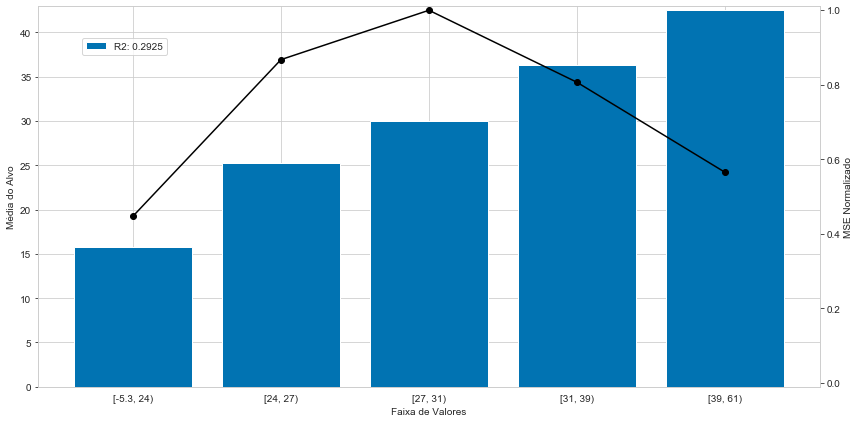

In [79]:
valores, qtds, qtds_alvo, qtd_unicos = unicos_qtds_alvos(vetor, alvo)
pts_corte, qtds_corte, qtds_alvo_corte = pontos_corte_alvo(qtds, qtd_unicos, qtds_alvo, num_div = 5)

valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)

mse_norm = calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte)

ymax = np.max(qtds_alvo_corte/qtds_corte)*1.01
y2max = np.max(qtds_corte)*1.01
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [14, 7])
    mse = np.mean(np.power(alvo, 2)) - np.sum(np.power(qtds_alvo_corte, 2)/qtds_corte)/np.sum(qtds_corte)
    r2 = 1 - mse/mse_ini
    ax.bar(strings_intervalos, qtds_alvo_corte/qtds_corte, color = paleta_cores[0], label = 'R2: ' + '%.4g' % r2)
    ax.set_xlabel('Faixa de Valores')
    ax.set_ylabel('Média do Alvo')
    ax.set_ylim(bottom = 0.0)
    ax.set_ylim(top = ymax)
    ax.legend(bbox_to_anchor = (0.05, 0.93), loc='upper left')
    ax2 = ax.twinx()
    ax2.grid(False)
    #ax2.plot(strings_intervalos, qtds_corte, 'o-', color = 'black')
    #ax2.set_ylabel('Quantidade de Exemplos')
    #ax2.set_ylim(top = y2max)
    ax2.plot(strings_intervalos, mse_norm, 'o-', color = 'black')
    ax2.set_ylim(top = 1.01)
    ax2.set_ylabel('MSE Normalizado')
    ax2.set_ylim(bottom = -0.01)
    plt.show()

In [80]:
def minimiza_mse(pts_corte, qtds_corte, qtds, qtds_alvo_corte, qtds_alvo, qtd_unicos):
    fim = pts_corte.size - 1
    prefim = fim - 1
    permutado = True
    lista_plots = [] # ALTERADO
    while(permutado):
        
        # ALTERADO
        valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
        strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
        mse_norm = calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte)
        for k in range(0, 1):
            lista_plots.append(('ini_loop', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy(), mse_norm))
        #########
        
        permutado = False
        for i in range(fim): # ALTERADO
            Qe = qtds_corte[prefim-i]
            Qd = qtds_corte[fim-i]
            Ae = qtds_alvo_corte[prefim-i]
            Ad = qtds_alvo_corte[fim-i]
            p = pts_corte[prefim-i]
            
            p_inf = 0 if i == prefim else pts_corte[prefim-i-1]
            e = p
            while(permutado == False and e > p_inf):
                qe = np.sum(qtds[e:p+1])
                ae = np.sum(qtds_alvo[e:p+1])
                if(Qe > qe and funcao_comparacao_mse(Qe-qe, Ae-ae, Qd+qe, Ad+ae) < funcao_comparacao_mse(Qe, Ae, Qd, Ad)):
                    qtds_corte[fim-i] = Qd + qe
                    qtds_corte[prefim-i] = Qe - qe
                    qtds_alvo_corte[fim-i] = Ad + ae
                    qtds_alvo_corte[prefim-i] = Ae - ae
                    pts_corte[prefim-i] = e - 1
                    permutado = True

                    # ALTERADO
                    valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
                    strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
                    mse_norm = calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte)
                    lista_plots.append(('', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy(), mse_norm))
                    #########
                else:
                    e = e - 1
            
            p_sup = pts_corte[fim-i]
            d = p+1
            while(permutado == False and d < p_sup):
                qd = np.sum(qtds[p+1:d+1])
                ad = np.sum(qtds_alvo[p+1:d+1])
                if(Qd > qd and funcao_comparacao_mse(Qe+qd, Ae+ad, Qd-qd, Ad-ad) < funcao_comparacao_mse(Qe, Ae, Qd, Ad)):
                    qtds_corte[fim-i] = Qd - qd
                    qtds_corte[prefim-i] = Qe + qd
                    qtds_alvo_corte[fim-i] = Ad - ad
                    qtds_alvo_corte[prefim-i] = Ae + ad
                    pts_corte[prefim-i] = d
                    permutado = True

                    # ALTERADO
                    valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
                    strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)
                    mse_norm = calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte)
                    lista_plots.append(('', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy(), mse_norm))
                    #########
                else:
                    d = d + 1
                
    return pts_corte, qtds_corte, qtds_alvo_corte, lista_plots # ALTERADO

In [81]:
pts_corte, qtds_corte, qtds_alvo_corte, lista_plots = minimiza_mse(pts_corte, qtds_corte, qtds, qtds_alvo_corte, qtds_alvo, qtd_unicos)
valores_min, valores_max = trf.calcula_valores_corte(valores, pts_corte)
strings_intervalos = calcula_intervalos_algasignif(valores_min, valores_max)

mse_norm = calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte)

for k in range(0, 10):
    lista_plots.append(('fim', strings_intervalos, qtds_corte.copy(), qtds_alvo_corte.copy(), mse_norm))

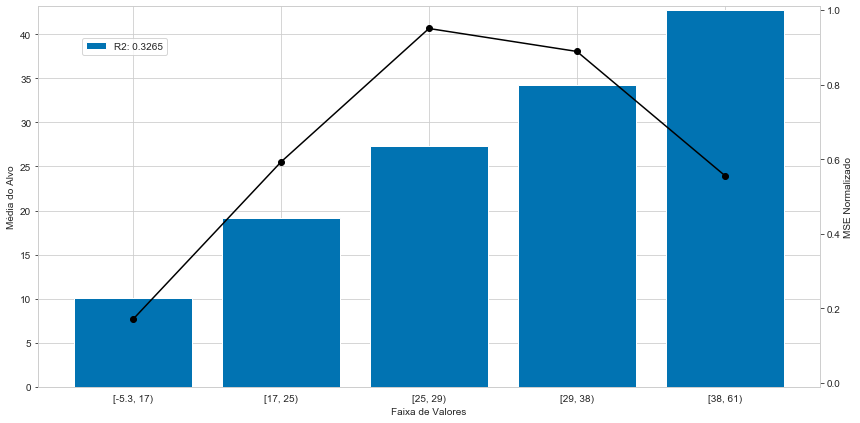

In [82]:
mse_norm = calcula_mse_normalizado(vetor, valores_max, alvo, qtds_alvo_corte, qtds_corte)

ymax = np.max(qtds_alvo_corte/qtds_corte)*1.01
y2max = np.max(qtds_corte)*1.01
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [14, 7])
    mse = np.mean(np.power(alvo, 2)) - np.sum(np.power(qtds_alvo_corte, 2)/qtds_corte)/np.sum(qtds_corte)
    r2 = 1 - mse/mse_ini
    ax.bar(strings_intervalos, qtds_alvo_corte/qtds_corte, color = paleta_cores[0], label = 'R2: ' + '%.4g' % r2)
    ax.set_xlabel('Faixa de Valores')
    ax.set_ylabel('Média do Alvo')
    ax.set_ylim(bottom = 0.0)
    ax.set_ylim(top = ymax)
    ax.legend(bbox_to_anchor = (0.05, 0.93), loc='upper left')
    ax2 = ax.twinx()
    ax2.grid(False)
    #ax2.plot(strings_intervalos, qtds_corte, 'o-', color = 'black')
    #ax2.set_ylabel('Quantidade de Exemplos')
    #ax2.set_ylim(top = y2max)
    ax2.plot(strings_intervalos, mse_norm, 'o-', color = 'black')
    ax2.set_ylim(top = 1.01)
    ax2.set_ylabel('MSE Normalizado')
    ax2.set_ylim(bottom = -0.01)
    plt.show()

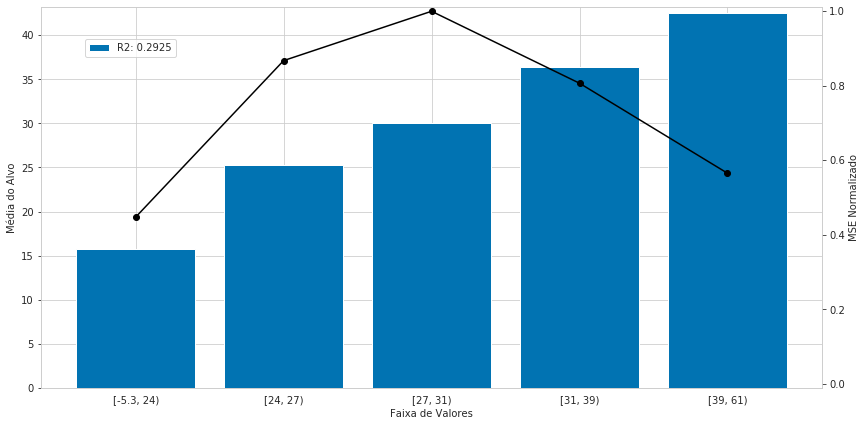

In [83]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = [14, 7])
    ax2 = ax.twinx()
    
y2max = 0
for l in lista_plots:
    y2max = max(y2max, np.max(l[2]))
y2max = y2max*1.01
    
def animate(i):
    qtds_plot = lista_plots[i][2]
    strings_intervalos_plot = lista_plots[i][1]
    qtds_alvo_plot = lista_plots[i][3]
    mse_norm_plot = lista_plots[i][4]
    flag_color = lista_plots[i][0]
    mse = np.mean(np.power(alvo, 2)) - np.sum(np.power(qtds_alvo_plot, 2)/qtds_plot)/np.sum(qtds_plot)
    r2 = 1 - mse/mse_ini
    with sns.axes_style("whitegrid"):
        ax.cla()
        ax2.cla()
        if(flag_color == 'ini_loop'):
            ax.bar(strings_intervalos_plot, qtds_alvo_plot/qtds_plot, color = paleta_cores[0], label = 'R2: ' + '%.4g' % r2)
        elif(flag_color == 'fim'):
            ax.bar(strings_intervalos_plot, qtds_alvo_plot/qtds_plot, color = paleta_cores[2], label = 'R2: ' + '%.4g' % r2)
        else:
            ax.bar(strings_intervalos_plot, qtds_alvo_plot/qtds_plot, color = paleta_cores[0], label = 'R2: ' + '%.4g' % r2)
        ax.legend(bbox_to_anchor = (0.05, 0.93), loc='upper left')
        ax.set_xlabel('Faixa de Valores')
        ax.set_ylabel('Média do Alvo')
        ax.set_ylim(bottom = 0.0)
        ax.set_ylim(top = ymax)
        ax2.grid(False)
        #ax2.plot(strings_intervalos, qtds_corte, 'o-', color = 'black')
        #ax2.set_ylabel('Quantidade de Exemplos')
        #ax2.set_ylim(top = y2max)
        ax2.plot(strings_intervalos_plot, mse_norm_plot, 'o-', color = 'black')
        ax2.set_ylim(top = 1.01)
        ax2.set_ylabel('MSE Normalizado')
        ax2.set_ylim(bottom = -0.01)

anim = animation.FuncAnimation(fig, animate, frames = len(lista_plots), interval = 1000, blit = False, repeat = True)
plt.show()
anim.save('imagens/ilustracao_algoritmo_mse.gif', writer = 'pillow', fps = 5)